# 04 · Sélection de variables (Phase 4)
Code : `src/selection.py` (calcul, ~15 min, cache par pli) et `src/selection_report.py` (tableau + figures).

Protocole : 60 000 annonces du train, CV 5 plis groupée par hôte ; prétraitement et sélection ajustés sur le train de chaque pli ; évaluation LightGBM (Ridge en témoin).

In [1]:
from pathlib import Path
from IPython.display import Image, Markdown, display
import pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
display(Markdown((ROOT/'reports'/'selection_table.md').read_text(encoding='utf-8')))

# Phase 4 : sélection de variables (tableau final)

Cible : log(price_eur). Candidates : jeu `core+quote+quality` après prétraitement (target encoding du quartier, one-hot). Échantillon de 60 000 annonces du train, CV 5 plis groupée par hôte ; prétraitement et sélection ajustés sur le train de chaque pli. Modèle commun d'évaluation : LightGBM (200 arbres) ; Ridge en témoin.

| Méthode                                  | Famille        |   Nb variables | RMSE LightGBM (CV)   |   MAE LightGBM |   RMSE Ridge |   MAE Ridge |   Temps sélection (s) |   Temps entraînement (s) | Stabilité (Jaccard)   |
|:-----------------------------------------|:---------------|---------------:|:---------------------|---------------:|-------------:|------------:|----------------------:|-------------------------:|:----------------------|
| Toutes les variables (référence)         | témoin         |            259 | 0.3854 ± 0.0036      |         0.2746 |       0.4288 |      0.3104 |                   0   |                      0.9 | 1.00                  |
| 60 variables aléatoires (témoin)         | témoin         |             60 | 0.4812 ± 0.0435      |         0.3572 |       0.5839 |      0.4426 |                   0   |                      0.4 | 0.13                  |
| Variance quasi nulle (>99,5 % identique) | filtre         |            251 | 0.3857 ± 0.0036      |         0.2748 |       0.4289 |      0.3105 |                   0.2 |                      0.9 | 1.00                  |
| Corrélation (f_regression, k=60)         | filtre         |             60 | 0.4293 ± 0.0051      |         0.3113 |       0.4728 |      0.3464 |                   0.1 |                      0.4 | 0.91                  |
| Information mutuelle (k=60)              | filtre         |             60 | 0.3966 ± 0.0036      |         0.2834 |       0.4613 |      0.3372 |                   2.9 |                      0.5 | 0.84                  |
| ANOVA F sur tercile de prix (k=60)       | filtre         |             60 | 0.4318 ± 0.0054      |         0.3125 |       0.4724 |      0.346  |                   0.2 |                      0.4 | 0.97                  |
| Chi² sur tercile de prix (k=60)          | filtre         |             60 | 0.4796 ± 0.0054      |         0.3531 |       0.5143 |      0.3822 |                   0.4 |                      0.4 | 0.95                  |
| RFECV (Ridge)                            | wrapper        |            131 | 0.3875 ± 0.0040      |         0.2764 |       0.4302 |      0.3114 |                   1.6 |                      0.7 | 0.59                  |
| SFS avant (Ridge, 25 parmi 80)           | wrapper        |             25 | 0.4313 ± 0.0066      |         0.314  |       0.4719 |      0.3463 |                  87.2 |                      0.2 | 0.53                  |
| Lasso (LassoCV)                          | embedded       |            226 | 0.3876 ± 0.0039      |         0.2765 |       0.4288 |      0.3104 |                  11.2 |                      0.7 | 0.85                  |
| Elastic Net (CV)                         | embedded       |            227 | 0.3875 ± 0.0039      |         0.2763 |       0.4288 |      0.3104 |                  39.5 |                      0.8 | 0.85                  |
| LightGBM gain (95 % cumulé)              | embedded       |             39 | 0.3912 ± 0.0043      |         0.2794 |       0.4563 |      0.3335 |                   0.9 |                      0.4 | 0.86                  |
| Random Forest impurité (95 % cumulé)     | embedded       |             79 | 0.3884 ± 0.0044      |         0.2774 |       0.4387 |      0.3191 |                   1.7 |                      0.6 | 0.82                  |
| Permutation (LightGBM, split interne)    | agnostique     |            143 | 0.3858 ± 0.0037      |         0.275  |       0.4365 |      0.3167 |                  22.4 |                      0.8 | 0.61                  |
| SHAP |moyenne| (95 % cumulé)             | agnostique     |             81 | 0.3876 ± 0.0040      |         0.2762 |       0.4401 |      0.32   |                   2.1 |                      0.6 | 0.84                  |
| VIF itératif (seuil 10)                  | colinéarité    |            236 | 0.3879 ± 0.0029      |         0.2773 |       0.4294 |      0.3108 |                   0.4 |                      0.8 | 0.96                  |
| PCA (95 % de variance)                   | transformation |            191 | 0.4507 ± 0.0027      |         0.3316 |       0.4433 |      0.3229 |                   0.2 |                      2.1 | —                     |
| PCA (60 composantes)                     | transformation |             60 | 0.4570 ± 0.0027      |         0.3379 |       0.4757 |      0.3528 |                   0.2 |                      0.7 | —                     |

Stabilité de Jaccard = moyenne des Jaccard sur les 10 paires de plis. « — » : non applicable (PCA, toutes variables).

## Variables retenues par le plus de méthodes sélectives (>= 3 plis sur 5 ; 7 méthodes : Corrélation (f_regression, k=60), Information mutuelle (k=60), ANOVA F sur tercile de prix (k=60), SFS avant (Ridge, 25 parmi 80), LightGBM gain (95 % cumulé), Random Forest impurité (95 % cumulé), SHAP |moyenne| (95 % cumulé))

|                           |   méthodes (sur 7) |
|:--------------------------|-------------------:|
| accommodates              |                  7 |
| nbhd_key                  |                  7 |
| am_dishwasher             |                  7 |
| bath_count                |                  7 |
| am_lock_on_bedroom_door   |                  7 |
| city_paris                |                  7 |
| bedrooms                  |                  7 |
| bath_per_person           |                  7 |
| city_mexico-city          |                  7 |
| bath_shared               |                  7 |
| review_scores_location    |                  7 |
| host_entire_share         |                  6 |
| persons_per_bedroom       |                  6 |
| n_amenities               |                  6 |
| log_min_nights            |                  6 |
| room_type_Entire home/apt |                  6 |
| am_elevator               |                  6 |
| room_type_Private room    |                  6 |
| quote_nights              |                  6 |
| has_license               |                  6 |
| am_hair_dryer             |                  5 |
| am_tv                     |                  5 |
| beds_per_person           |                  5 |
| city_tokyo                |                  5 |
| am_crib                   |                  5 |

## Importances moyennes (rang 1 = plus important)

|                           |   rf_impurity |   lgb_gain |   permutation |   shap |
|:--------------------------|--------------:|-----------:|--------------:|-------:|
| nbhd_key                  |             1 |          1 |             1 |      1 |
| accommodates              |             2 |          2 |             3 |      2 |
| quote_nights              |             9 |          5 |             2 |      3 |
| bedrooms                  |             3 |          3 |             4 |      4 |
| dist_center_km            |            14 |         12 |             6 |      5 |
| latitude                  |             5 |          7 |             7 |      6 |
| bath_count                |             4 |          4 |             5 |      7 |
| log_quote_lead_days       |            18 |          8 |             8 |      8 |
| bath_shared               |             7 |          6 |            10 |      9 |
| am_dishwasher             |            20 |         13 |            15 |     10 |
| city_new-york-city        |            25 |          9 |             9 |     11 |
| review_scores_location    |            19 |         14 |            13 |     12 |
| review_scores_cleanliness |            26 |         19 |            16 |     13 |
| room_type_Entire home/apt |             6 |         10 |            14 |     14 |
| host_entire_share         |            16 |         21 |            17 |     15 |
| longitude                 |             8 |         11 |            11 |     16 |
| quote_is_weekend          |            53 |         28 |            18 |     17 |
| city_mexico-city          |            13 |         17 |            12 |     18 |
| review_scores_value       |            36 |         33 |            19 |     19 |
| am_air_conditioning       |            43 |         31 |            20 |     20 |



## Erreur selon le nombre de variables

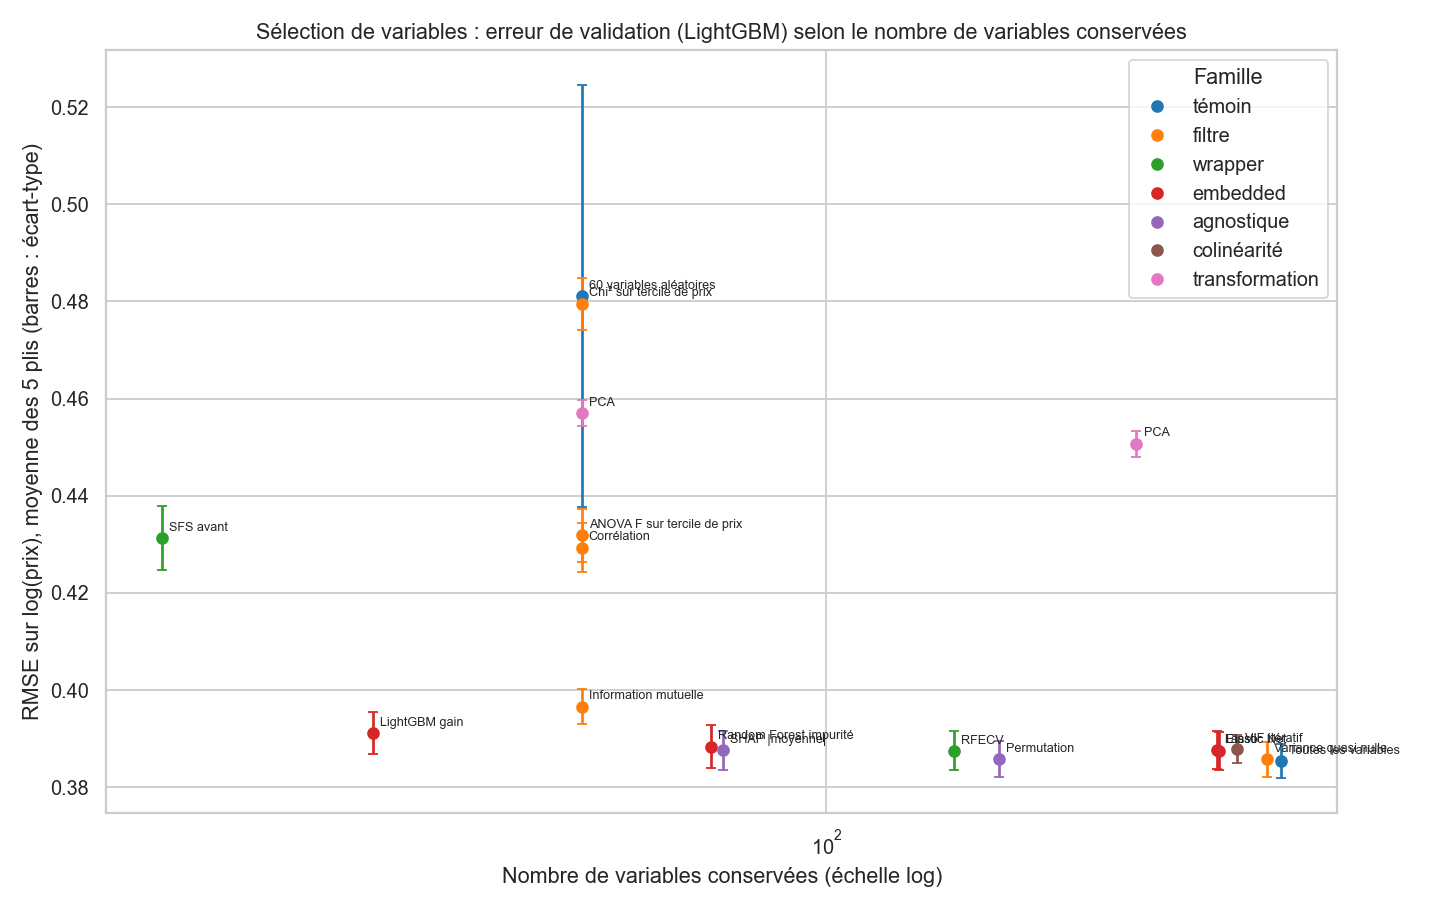

In [2]:
display(Image(ROOT/'reports'/'figures'/'sel_01_rmse_vs_nfeatures.png'))

## Consensus entre méthodes sélectives

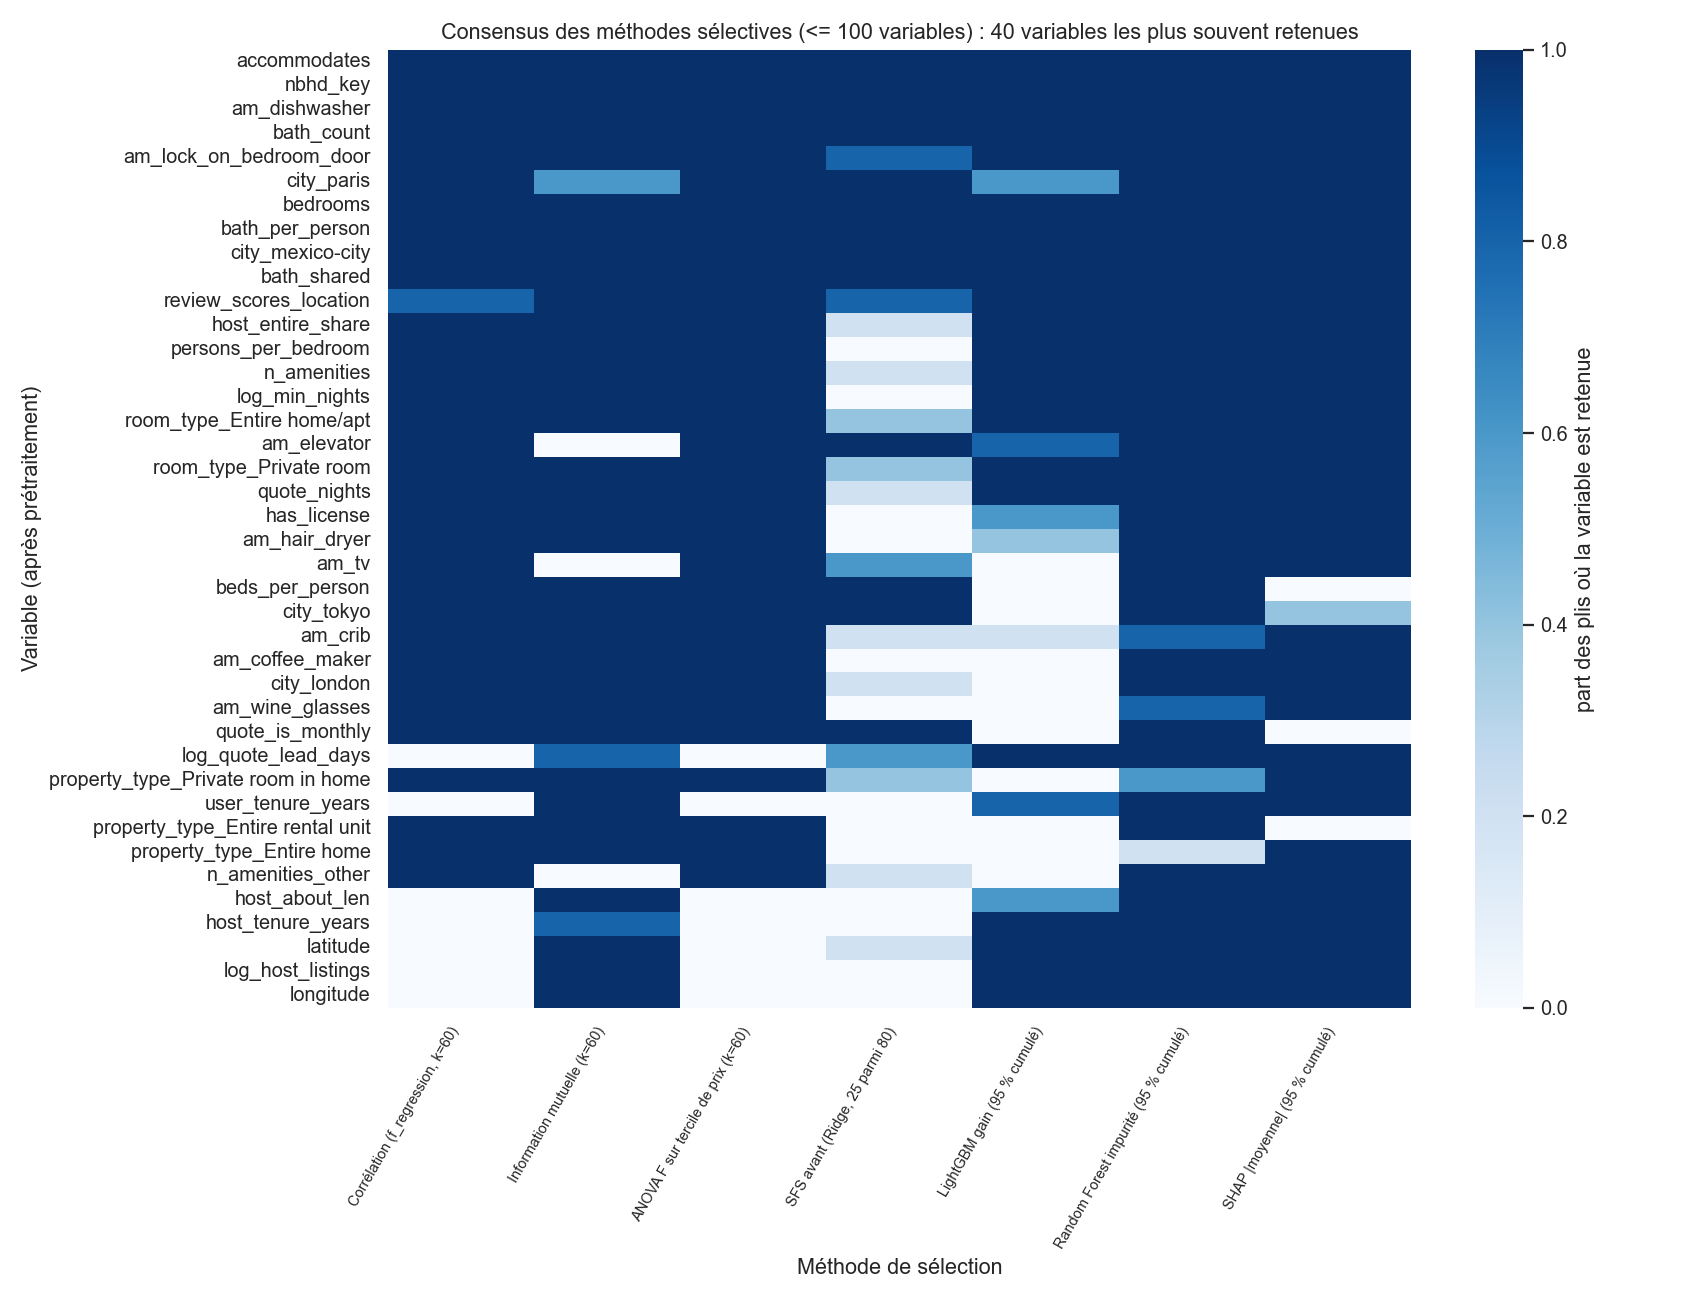

In [3]:
display(Image(ROOT/'reports'/'figures'/'sel_02_consensus.png'))

## Biais des importances (rangs selon la mesure)

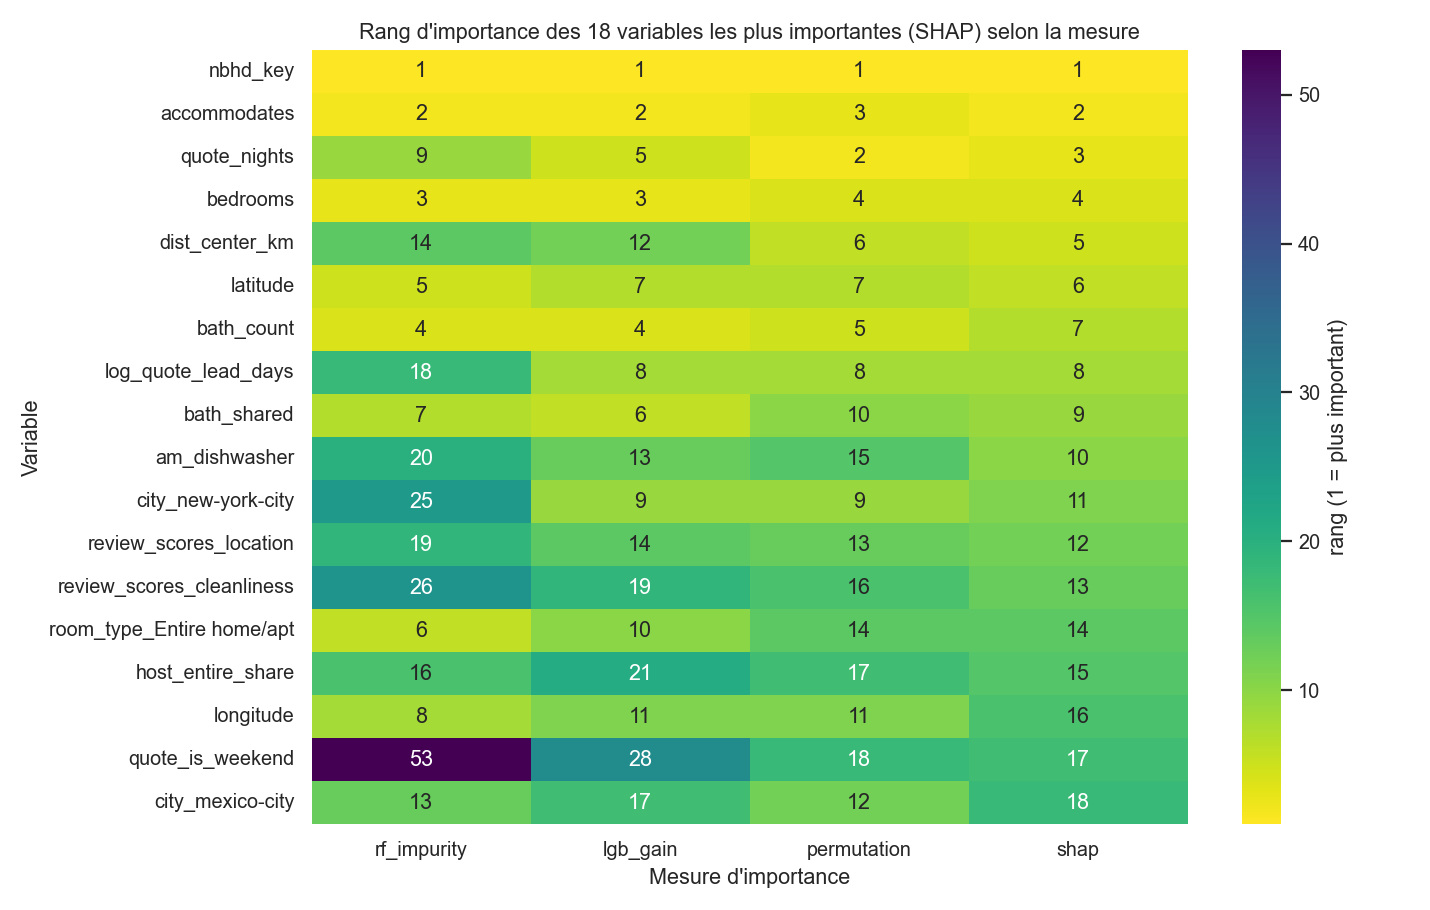

In [4]:
display(Image(ROOT/'reports'/'figures'/'sel_03_importance_ranks.png'))

## Discussion

In [5]:
display(Markdown((ROOT/'reports'/'selection_discussion.md').read_text(encoding='utf-8')))

# Phase 4 : discussion de la sélection de variables

Tous les chiffres viennent de `reports/selection_results.csv`, `selection_importances.csv` et `selection_frequency.csv` (5 plis groupés par hôte, 60 000 annonces du train).

## Lecture du tableau
- **Référence (toutes les variables, 259 colonnes après prétraitement)** : RMSE LightGBM 0,3854. Un tirage de 60 variables au hasard donne 0,4812 : la sélection a donc un vrai sens.
- **Aucune méthode ne bat la référence.** LightGBM supporte bien les variables peu utiles ; le gain d'une sélection est la simplicité et l'interprétabilité, pas la performance.
- **Meilleur compromis** : SHAP (95 % de l'importance cumulée) garde 81 variables pour 0,3876 (+0,002 vs référence) ; LightGBM-gain en garde 39 pour 0,3912 (+0,006). La permutation (143 variables, 0,3858) et RFECV (131, 0,3875) restent aussi proches.
- **Les filtres univariés sont les moins bons à k = 60** : corrélation 0,4293, ANOVA 0,4318, et surtout chi² 0,4796 (proche du hasard ; explication probable, non testée : le chi² sur variables min-max et tercile de prix favorise des indicatrices peu liées au prix). L'information mutuelle (0,3966) est nettement meilleure car elle capte les relations non linéaires (latitude, longitude, encodage du quartier). Un filtre univarié ignore les interactions et la redondance.
- **Wrappers** : RFECV (Ridge) garde 131 variables, performance équivalente à la référence. Le SFS avant, limité à 25 variables parmi 80 pré-filtrées et guidé par un modèle linéaire, est mauvais pour LightGBM (0,4313) et coûteux (87 s contre < 3 s pour les filtres) : la sélection guidée par Ridge ne retient pas les variables utiles à un modèle non linéaire.
- **Embedded linéaires** : Lasso (226) et Elastic Net (227) ne suppriment presque rien, car les 259 colonnes portent toutes un peu d'information ; pour Ridge, la référence reste la meilleure (0,4288).
- **VIF (seuil 10)** : ne retire que 23 colonnes sur 259, sans effet sur l'erreur (0,3879) : la multicolinéarité est faible une fois les colonnes parfaitement redondantes retirées, et elle gêne l'interprétation des coefficients linéaires, pas la prédiction des arbres.
- **PCA (transformation)** : 0,4507 avec 191 composantes (95 % de variance) et 0,4570 avec 60, nettement pire que la sélection. Hypothèse (non testée) : les axes de variance maximale ne sont pas ceux qui expliquent le prix ; la PCA détruit en outre l'interprétabilité. À réserver à la visualisation (phase 8).

## Stabilité (Jaccard moyen sur les 10 paires de plis)
Filtres univariés : 0,84 à 0,97 (très stables). Embedded : 0,82 à 0,86. VIF : 0,96. Wrappers et permutation : 0,53 à 0,61, moins stables (RFECV 0,59, SFS 0,53, permutation 0,61), car ils dépendent de petits écarts de performance entre sous-ensembles et du bruit de l'échantillon de validation interne. Un sous-ensemble stable n'est pas pour autant meilleur (chi² : Jaccard 0,95 mais mauvaise erreur).

## Variables retenues par plusieurs méthodes
Consensus des 7 méthodes sélectives (≤ 100 variables, hors chi²) : retenues par les 7 méthodes dans au moins 3 plis sur 5 : `accommodates`, `bedrooms`, `bath_count`, `bath_per_person`, `bath_shared`, `nbhd_key` (quartier encodé), `am_dishwasher`, `am_lock_on_bedroom_door`, `review_scores_location`, `city_paris`, `city_mexico-city`. Les rangs d'importance (SHAP / permutation) placent en tête : `nbhd_key` (rang 1 pour toutes les mesures), `accommodates`, `quote_nights`, `bedrooms`, `bath_count`, `dist_center_km`, `latitude`, `log_quote_lead_days`.
Les variables du contexte du devis (`quote_nights`, `log_quote_lead_days`) sont parmi les plus importantes : le prix observé dépend beaucoup de la durée de séjour du devis (remises mensuelles).

## Divergences : biais des importances d'arbres
Rang d'importance selon la mesure (1 = plus important) :

| Variable | RF impureté | LightGBM gain | Permutation | SHAP |
|---|---:|---:|---:|---:|
| desc_len | 29 | 44 | 70 | 65 |
| desc_words | 31 | 45 | 78 | 67 |
| name_len | 30 | 46 | 66 | 44 |
| host_about_len | 34 | 40 | 68 | 36 |
| am_air_conditioning | 43 | 31 | 20 | 20 |
| quote_nights | 9 | 5 | 2 | 3 |

Les variables continues à forte cardinalité (longueurs de textes) sont **surévaluées par l'impureté RF** (rang ≈ 30) par rapport à la permutation (rang ≈ 70) : un arbre a beaucoup de seuils candidats pour ces variables et peut y ajuster du bruit. À l'inverse, des variables binaires utiles (climatisation) sont sous-évaluées par l'impureté (rang 43) contre 20 en permutation et SHAP. La permutation et SHAP, calculées hors échantillon d'entraînement (permutation sur un split interne), sont plus fiables. Le quartier encodé (`nbhd_key`, forte cardinalité mais encodé par target encoding avec CV interne) reste premier pour toutes les mesures : la cohérence entre les mesures indique que ce n'est pas un artefact de cardinalité, mais cet encodage reste une variable puissante à surveiller en généralisation à une ville inconnue (phase 5).
La permutation répartit l'importance entre variables corrélées (latitude / longitude / distance au centre) : chacune paraît moins importante prise isolément.

## Décisions pour la suite
- **Jeu retenu pour la régression** : `core+quote+quality`. Les 81 variables SHAP (liste dans `models/selected_features.json`, clé `shap_95`) servent de jeu réduit pour les modèles linéaires, l'interprétation et les outils métier ; les modèles d'arbres de la phase 6 peuvent aussi utiliser toutes les variables.
- Les variables d'activité (`activity`) restent exclues (conséquences du prix).
- Phase 5 : tester sans `city_*` et sans `nbhd_key` pour mesurer l'effet ville.
- Limites : un échantillon de 60 000 annonces (12 % du train) ; une graine ; hyperparamètres fixes (200 arbres) ; k = 60 non optimisé pour les filtres ; SFS limité à 25 variables pré-filtrées ; RFECV et SFS utilisent Ridge en interne.
